In [1]:
from pathlib import Path
import os

ROOT = Path.cwd()

if not (ROOT / "data" / "raw" / "loan_data.csv").exists():
    ROOT = ROOT.parent

os.chdir(ROOT)

print("Project Root:", ROOT)
print("Dataset Found:", (ROOT / "data" / "raw" / "loan_data.csv").exists())

Project Root: C:\Users\Admin\.gemini\antigravity\brain\69d351d5-5bf5-4c61-af09-3cebe4e8f136\Loan-Approval-Prediction
Dataset Found: True


In [2]:
import pandas as pd

df = pd.read_csv("data/raw/loan_data.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

print("\nFirst 5 Records:")
display(df.head())

Dataset loaded successfully!
Dataset Shape: (614, 13)

First 5 Records:


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [3]:
print("MISSING VALUES:")
display(df.isnull().sum().to_frame("Missing Count"))

print("\nLOAN STATUS DISTRIBUTION:")
display(df["Loan_Status"].value_counts().to_frame("Count"))

print("\nLOAN STATUS PERCENTAGE:")
display(
    (df["Loan_Status"].value_counts(normalize=True) * 100)
    .round(2)
    .to_frame("Percentage")
)

MISSING VALUES:


,Missing Count
Loan_ID,0
Gender,13
Married,3
Dependents,15
Education,0
Self_Employed,32
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,22
Loan_Amount_Term,14



LOAN STATUS DISTRIBUTION:


,Count
Loan_Status,
Y,422
N,192



LOAN STATUS PERCENTAGE:


,Percentage
Loan_Status,
Y,68.73
N,31.27


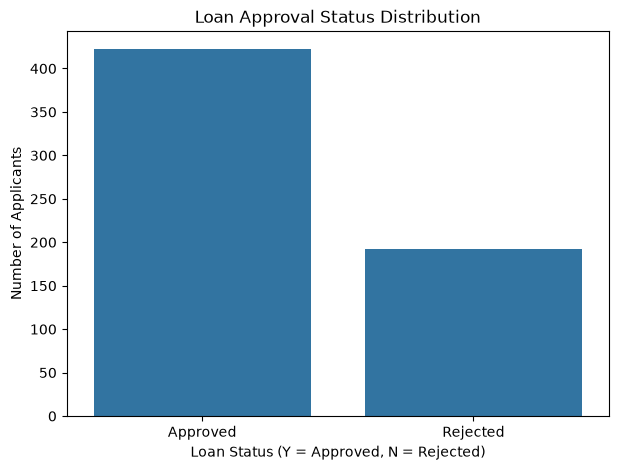

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Loan_Status"
)

plt.title("Loan Approval Status Distribution")
plt.xlabel("Loan Status (Y = Approved, N = Rejected)")
plt.ylabel("Number of Applicants")
plt.xticks([0, 1], ["Approved", "Rejected"])

plt.show()

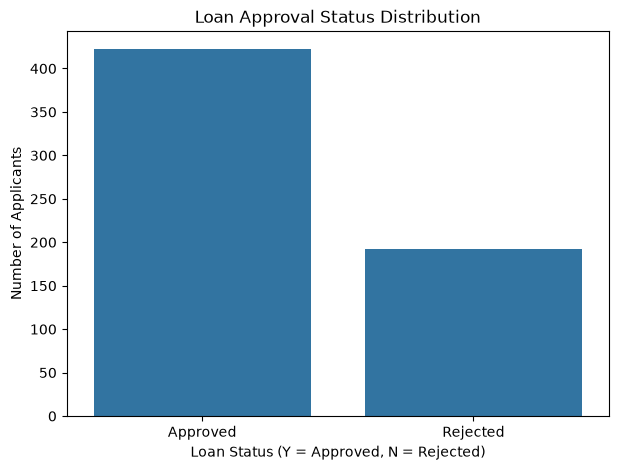

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Loan_Status"
)

plt.title("Loan Approval Status Distribution")
plt.xlabel("Loan Status (Y = Approved, N = Rejected)")
plt.ylabel("Number of Applicants")
plt.xticks([0, 1], ["Approved", "Rejected"])

plt.show()

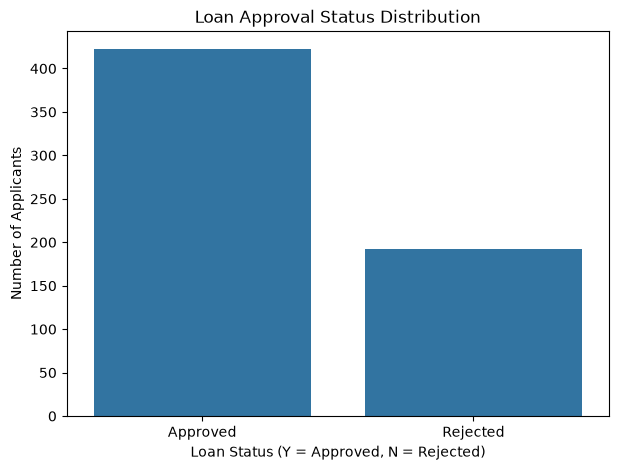

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Loan_Status"
)

plt.title("Loan Approval Status Distribution")
plt.xlabel("Loan Status (Y = Approved, N = Rejected)")
plt.ylabel("Number of Applicants")
plt.xticks([0, 1], ["Approved", "Rejected"])

plt.show()

In [7]:
from sklearn.model_selection import train_test_split
from src.data_preprocessing import prepare_features_target

# Separate input features and target variable
X, y = prepare_features_target(df)

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))

print("\nTarget Class Mapping:")
print("Y = 1 (Approved)")
print("N = 0 (Rejected)")

Features Shape: (614, 11)
Target Shape: (614,)

Training Samples: 491
Testing Samples: 123

Target Class Mapping:
Y = 1 (Approved)
N = 0 (Rejected)


In [8]:
from src.data_preprocessing import build_preprocessor

preprocessor = build_preprocessor(X_train)

# Fit preprocessing only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same preprocessing to testing data
X_test_processed = preprocessor.transform(X_test)

print("Data preprocessing completed successfully!")
print("Processed Training Shape:", X_train_processed.shape)
print("Processed Testing Shape:", X_test_processed.shape)

Data preprocessing completed successfully!
Processed Training Shape: (491, 20)
Processed Testing Shape: (123, 20)


In [9]:
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression model
model = LogisticRegression(
    solver="liblinear",
    max_iter=1000,
    random_state=42
)

# Train the model
model.fit(X_train_processed, y_train)

print("Logistic Regression Model trained successfully!")
print("Model Coefficients Shape:", model.coef_.shape)
print("Model Intercept:", model.intercept_)

Logistic Regression Model trained successfully!
Model Coefficients Shape: (1, 20)
Model Intercept: [0.17374231]


In [10]:
# Predict loan status
y_pred = model.predict(X_test_processed)

# Predict approval probabilities
y_prob = model.predict_proba(X_test_processed)[:, 1]

results = pd.DataFrame({
    "Actual Status": y_test.values,
    "Predicted Status": y_pred,
    "Approval Probability": y_prob.round(4)
})

print("First 10 Predictions:")
display(results.head(10))

First 10 Predictions:


,Actual Status,Predicted Status,Approval Probability
0,0,0,0.0544
1,1,1,0.8934
2,1,1,0.7475
3,1,1,0.7142
4,1,1,0.8856
5,0,1,0.8237
6,1,1,0.8826
7,1,1,0.8059
8,1,1,0.7101
9,1,1,0.7437


In [11]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

cm = confusion_matrix(y_test, y_pred)

tn, fp, fn, tp = cm.ravel()
specificity = tn / (tn + fp)

roc_auc = roc_auc_score(y_test, y_prob)

print("MODEL EVALUATION RESULTS")
print("------------------------")
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("Specificity:", round(specificity, 4))
print("F1 Score:", round(f1, 4))
print("ROC-AUC:", round(roc_auc, 4))

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Rejected", "Approved"]
))

MODEL EVALUATION RESULTS
------------------------
Accuracy: 0.8618
Precision: 0.84
Recall: 0.9882
Specificity: 0.5789
F1 Score: 0.9081
ROC-AUC: 0.8523

Confusion Matrix:
[[22 16]
 [ 1 84]]

Classification Report:
              precision    recall  f1-score   support

    Rejected       0.96      0.58      0.72        38
    Approved       0.84      0.99      0.91        85

    accuracy                           0.86       123
   macro avg       0.90      0.78      0.81       123
weighted avg       0.88      0.86      0.85       123



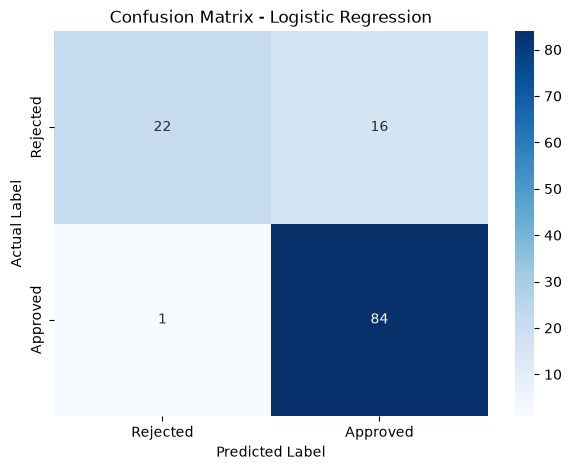

In [12]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Rejected", "Approved"],
    yticklabels=["Rejected", "Approved"]
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

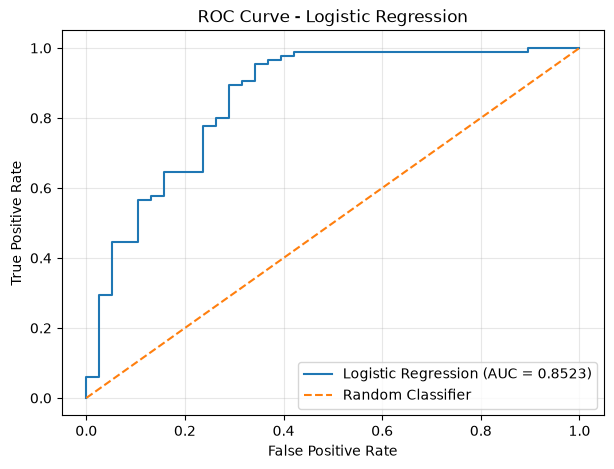

In [13]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {roc_auc:.4f})"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.title("ROC Curve - Logistic Regression")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [14]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

threshold_results = []

for threshold in [0.3, 0.5, 0.7]:
    predictions = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_test, predictions).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "Specificity": tn / (tn + fp),
        "F1 Score": f1_score(y_test, predictions, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Accuracy,Precision,Recall,Specificity,F1 Score
0,0.3,0.8618,0.840,0.9882,0.5789,0.9081
1,0.5,0.8618,0.840,0.9882,0.5789,0.9081
2,0.7,0.8130,0.869,0.8588,0.7105,0.8639


In [15]:
from sklearn.dummy import DummyClassifier

baseline_model = DummyClassifier(strategy="most_frequent")

baseline_model.fit(X_train_processed, y_train)

baseline_predictions = baseline_model.predict(X_test_processed)

baseline_accuracy = accuracy_score(y_test, baseline_predictions)

comparison = pd.DataFrame({
    "Model": ["Majority Class Baseline", "Logistic Regression"],
    "Accuracy": [
        baseline_accuracy,
        accuracy
    ]
})

display(comparison.round(4))

,Model,Accuracy
0,Majority Class Baseline,0.6911
1,Logistic Regression,0.8618


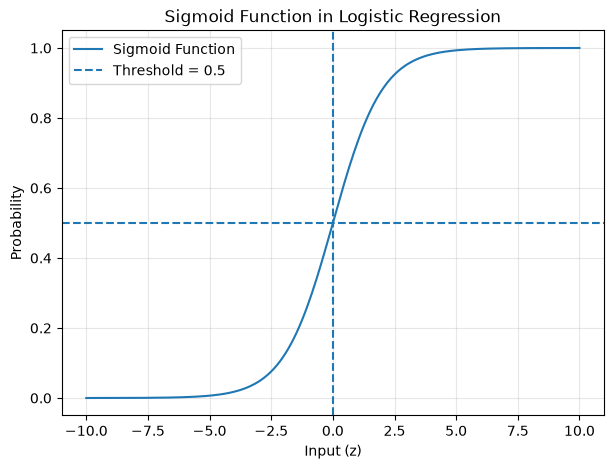

In [16]:
import numpy as np

z = np.linspace(-10, 10, 200)

sigmoid = 1 / (1 + np.exp(-z))

plt.figure(figsize=(7, 5))

plt.plot(z, sigmoid, label="Sigmoid Function")

plt.axhline(y=0.5, linestyle="--", label="Threshold = 0.5")
plt.axvline(x=0, linestyle="--")

plt.title("Sigmoid Function in Logistic Regression")
plt.xlabel("Input (z)")
plt.ylabel("Probability")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

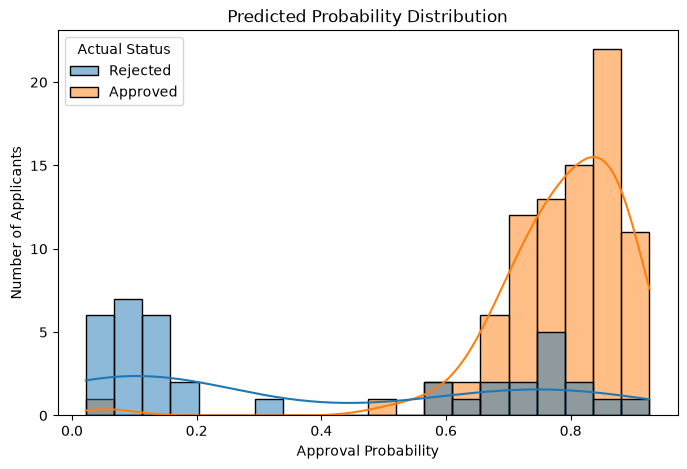

In [17]:
probability_df = pd.DataFrame({
    "Approval Probability": y_prob,
    "Actual Status": y_test.map({
        0: "Rejected",
        1: "Approved"
    }).values
})

plt.figure(figsize=(8, 5))

sns.histplot(
    data=probability_df,
    x="Approval Probability",
    hue="Actual Status",
    bins=20,
    kde=True,
    multiple="layer"
)

plt.title("Predicted Probability Distribution")
plt.xlabel("Approval Probability")
plt.ylabel("Number of Applicants")

plt.show()

In [18]:
feature_names = preprocessor.get_feature_names_out()

coefficient_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": model.coef_[0]
})

coefficient_df["Absolute Coefficient"] = (
    coefficient_df["Coefficient"].abs()
)

coefficient_df = coefficient_df.sort_values(
    by="Absolute Coefficient",
    ascending=False
)

display(coefficient_df.round(4))

,Feature,Coefficient,Absolute Coefficient
19,num__Credit_History,1.2479,1.2479
13,cat__Property_Area_Semiurban,0.5219,0.5219
3,cat__Married_Yes,0.3638,0.3638
6,cat__Dependents_2,0.3613,0.3613
5,cat__Dependents_1,-0.3426,0.3426
8,cat__Education_Graduate,0.2814,0.2814
12,cat__Property_Area_Rural,-0.2532,0.2532
10,cat__Self_Employed_No,0.1988,0.1988
2,cat__Married_No,-0.1901,0.1901
0,cat__Gender_Female,0.1756,0.1756


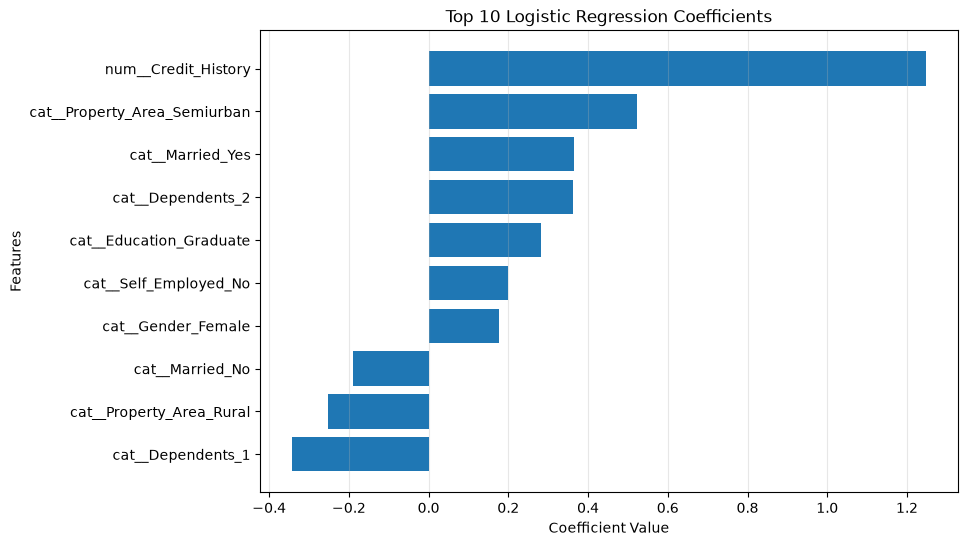

In [19]:
top_features = coefficient_df.head(10).sort_values(
    by="Coefficient"
)

plt.figure(figsize=(9, 6))

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

plt.title("Top 10 Logistic Regression Coefficients")
plt.xlabel("Coefficient Value")
plt.ylabel("Features")
plt.grid(axis="x", alpha=0.3)

plt.show()

In [20]:
sample = X_test.iloc[[0]]

sample_processed = preprocessor.transform(sample)

prediction = model.predict(sample_processed)[0]

probability = model.predict_proba(sample_processed)[0][1]

print("EXAMPLE LOAN PREDICTION")
print("-----------------------")
print("Predicted Status:", "Approved" if prediction == 1 else "Rejected")
print("Approval Probability:", round(probability * 100, 2), "%")
print("Actual Status:", "Approved" if y_test.iloc[0] == 1 else "Rejected")

EXAMPLE LOAN PREDICTION
-----------------------
Predicted Status: Rejected
Approval Probability: 5.44 %
Actual Status: Rejected


## Conclusion

The Loan Approval Prediction project was successfully implemented using Logistic Regression.

The dataset contains 614 records and 13 columns. Data preprocessing was performed using missing value imputation, One-Hot Encoding, and Standard Scaling.

The dataset was divided into 80% training data and 20% testing data. The Logistic Regression model achieved:

- Accuracy: 86.18%
- Precision: 84.00%
- Recall: 98.82%
- Specificity: 57.89%
- F1 Score: 90.81%
- ROC-AUC: 85.23%

The model achieved better accuracy than the majority-class baseline. Credit History was identified as an important feature influencing loan approval predictions.

The project demonstrates how Machine Learning can be used to predict loan approval status based on applicant information. However, the model is intended for academic purposes and requires further validation before real-world financial use.